In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2: Load the images

In [3]:
PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "dataset" / "processed"

IMG_SIZE = (224, 224)
BATCH_SIZE = 8
SEED = 42

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "validation"
TEST_DIR = DATA_DIR / "test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Class names:", class_names)

Found 1506 files belonging to 3 classes.
Found 323 files belonging to 3 classes.
Found 323 files belonging to 3 classes.
Class names: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


## Step 3: Apply MobileNetV2 preprocessing
Unlike our baseline CNN, MobileNetV2 uses pixel values scaled to approximately -1 to 1, rather than 0 to 1.

In [4]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

train_ds = train_ds.map(
    lambda images, labels: (preprocess_input(images), labels)
)

val_ds = val_ds.map(
    lambda images, labels: (preprocess_input(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (preprocess_input(images), labels)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Preprocessing completed!")

Preprocessing completed!


## Step 4: Load MobileNetV2
We'll use weights learned from ImageNet and remove its original classification layer so we can train it for our three potato leaf classes.

In [5]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))

MobileNetV2 loaded successfully!
Total layers: 154


ou now have 154 pretrained layers, all frozen. This means we'll initially use the knowledge it learned from ImageNet without changing those weights.

## Step 5: Build the MobileNetV2 classification model
We'll add a new classification head for our three potato leaf categories.

In [6]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    3,
    activation="softmax"
)(x)

mobilenet_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs
)

mobilenet_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Component	Parameters

MobileNetV2 pretrained base	2,257,984

Classification head	3,843

Total parameters	2,261,827

Trainable parameters	3,843

Non-trainable parameters	2,257,984

Important: Only 3,843 parameters are trainable at this stage. The pretrained MobileNetV2 layers remain frozen.

This is called transfer learning: we reuse previously learned image features and train a new classification head for our potato leaf dataset.

## Step 6: Calculate class weights
We'll use the same class-weighting approach as our baseline CNN to account for the imbalance.

In [7]:
from sklearn.utils.class_weight import compute_class_weight

train_labels = np.concatenate([
    labels.numpy() for images, labels in train_ds
])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=train_labels
)

class_weights = dict(enumerate(class_weights_array))

print("Class weights:")
for index, weight in class_weights.items():
    print(f"{class_names[index]}: {weight:.3f}")

Class weights:
Potato___Early_blight: 0.717
Potato___Late_blight: 0.717
Potato___healthy: 4.736


The class weights match the baseline CNN, so we're accounting for the class imbalance consistently.

## Step 7: Compile the MobileNetV2 model

In [8]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 model compiled successfully!")

MobileNetV2 model compiled successfully!


## Step 8: Set up training callbacks
We'll save the best MobileNetV2 model and stop training if validation performance stops improving

In [9]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

Path("../models").mkdir(parents=True, exist_ok=True)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

model_checkpoint = ModelCheckpoint(
    filepath="../models/mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks = [early_stopping, model_checkpoint]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


## Step 9: Train MobileNetV2
We'll allow up to 15 epochs. Early stopping will automatically stop training if validation loss does not improve.

In [10]:
EPOCHS = 10

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

c:\Users\Admin\Documents\Potato_Leaf_Disease_Project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - accuracy: 0.8121 - loss: 0.4230
Epoch 1: val_loss improved from None to 0.14011, saving model to ../models/mobilenetv2.keras

Epoch 1: finished saving model to ../models/mobilenetv2.keras
189/189 ━━━━━━━━━━━━━━━━━━━━ 96s 410ms/step - accuracy: 0.8121 - loss: 0.4230 - val_accuracy: 0.9659 - val_loss: 0.1401
Epoch 2/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - accuracy: 0.9462 - loss: 0.1476
Epoch 2: val_loss improved from 0.14011 to 0.09848, saving model to ../models/mobilenetv2.keras

Epoch 2: finished saving model to ../models/mobilenetv2.keras
189/189 ━━━━━━━━━━━━━━━━━━━━ 116s 614ms/step - accuracy: 0.9462 - loss: 0.1476 - val_accuracy: 0.9690 - val_loss: 0.0985
Epoch 3/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.9688 - loss: 0.0921
Epoch 3: val_loss improved from 0.09848 to 0.08767, saving model to ../models/mobilenetv2.keras

Epoch 3: finished saving model to ../models/mobilenetv2.keras
189/189 ━━━━━━━━━━━━━

## Step 10: Visualize training performance

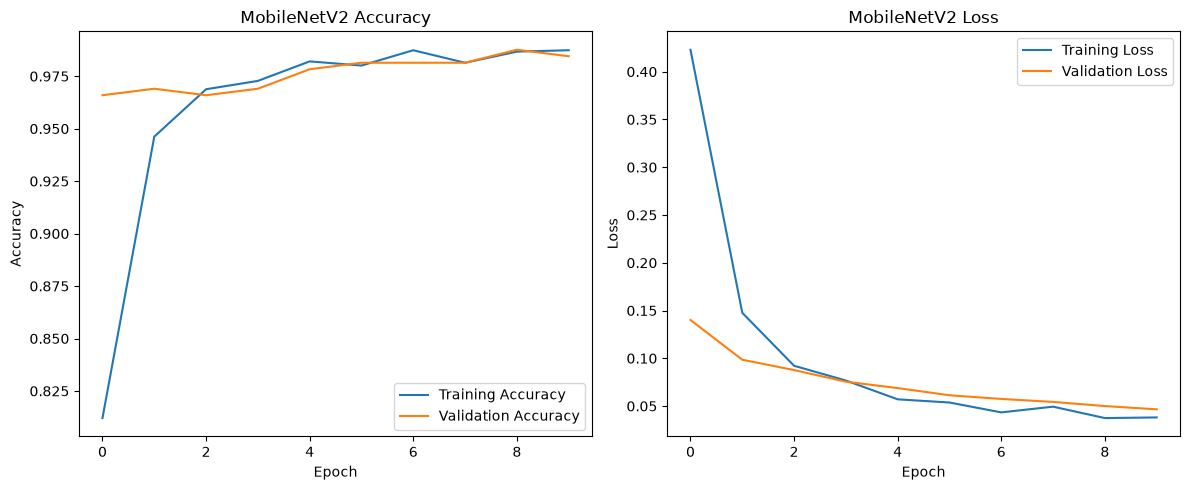

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history["accuracy"], label="Training Accuracy")
plt.plot(history_mobilenet.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mobilenet.history["loss"], label="Training Loss")
plt.plot(history_mobilenet.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

What the graphs tell us
1. Training accuracy: Increased from approximately 81% to 98.74%.
2. Validation accuracy: Remained consistently high and reached 98.45%.
3. Training loss: Decreased steadily, indicating that the model improved its predictions.
4. Validation loss: Also decreased throughout training, with no obvious sign of overfitting.
One important observation: validation accuracy starts higher than training accuracy. This is not necessarily a problem. Training includes data augmentation and dropout, which make the training task more challenging.

Conclusion: MobileNetV2 demonstrates strong learning and generalization on the validation dataset. However, we need the independent test results before deciding how well it performs overall.

## Step 11: Evaluate MobileNetV2 on the test dataset

In [13]:
test_loss, test_accuracy = mobilenet_model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 8s 166ms/step - accuracy: 0.9690 - loss: 0.0895
Test Loss: 0.0895
Test Accuracy: 0.9690
Test Accuracy: 96.90%


## Step 12: Generate the classification report

In [14]:
y_pred_prob = mobilenet_model.predict(test_ds)

y_pred = np.argmax(y_pred_prob, axis=1)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

41/41 ━━━━━━━━━━━━━━━━━━━━ 9s 184ms/step
                       precision    recall  f1-score   support

Potato___Early_blight     0.9932    0.9667    0.9797       150
 Potato___Late_blight     0.9487    0.9867    0.9673       150
     Potato___healthy     0.9524    0.8696    0.9091        23

             accuracy                         0.9690       323
            macro avg     0.9647    0.9410    0.9520       323
         weighted avg     0.9696    0.9690    0.9689       323



What these results mean:
- Early blight: Very high precision. When the model predicts early blight, it is usually correct.
- Late blight: Highest recall at 98.67%. It identifies almost all actual late blight images.
- Healthy: Recall is 86.96%. The model identifies 20 of the 23 healthy images correctly.
The healthy class has only 23 test images, so its metrics should be interpreted cautiously.

Comparison with your baseline CNN
MobileNetV2 performs better
Metric	Baseline CNN	MobileNetV2
Test accuracy	82.35%	96.90%
Macro F1-score	80.64%	95.20%
Weighted F1-score	81.85%	96.89%

This is a substantial improvement.

## Step 14: Generate the MobileNetV2 confusion matrix

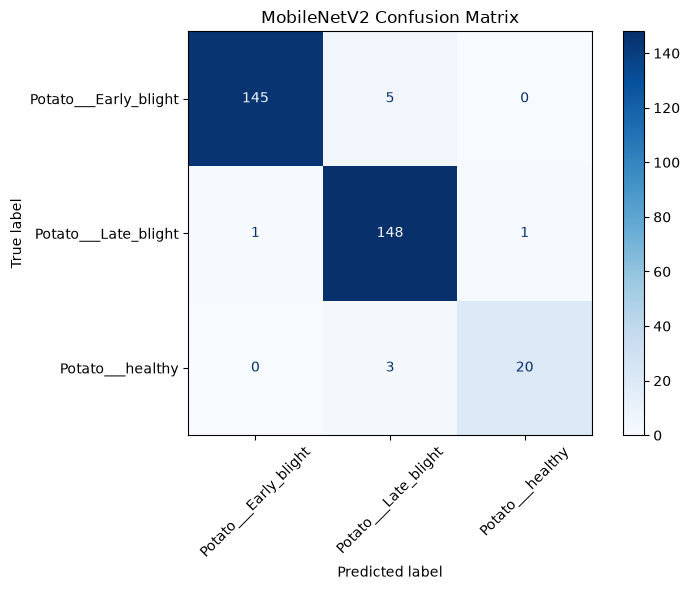

In [15]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    xticks_rotation=45
)

plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 15: Interpret the confusion matrix
313 out of 323 correct
Actual class	Predicted correctly	Misclassified
Early blight	145/150	5
Late blight	148/150	2
Healthy	20/23	3
Total	313/323	10

Key observations:
1. Early blight: 145 images were correctly classified. Five were mistaken for late blight.
2. Late blight: 148 images were correctly classified. Only two were misclassified.
3. Healthy: 20 images were correctly classified. Three were mistaken for late blight.
The model's strongest class by recall is late blight at 98.67%.
Comparing the two models
Your results so far:
- Baseline CNN: 82.35% test accuracy.
- MobileNetV2: 96.90% test accuracy.
MobileNetV2 has demonstrated a substantial improvement, particularly in distinguishing early and late blight.

One limitation to document: PlantVillage images are collected under relatively controlled conditions. Performance on real farm photographs may be lower, so this model should not yet be presented as a field-ready diagnostic tool.

## Step 16: Save MobileNetV2 evaluation results

In [16]:
mobilenet_results = pd.DataFrame({
    "Model": ["MobileNetV2"],
    "Test Accuracy": [test_accuracy],
    "Test Loss": [test_loss],
    "Macro F1 Score": [0.9520],
    "Weighted F1 Score": [0.9689]
})

mobilenet_results.to_csv(
    "../dataset/mobilenetv2_results.csv",
    index=False
)

print(mobilenet_results)
print("\nResults saved successfully!")

         Model  Test Accuracy  Test Loss  Macro F1 Score  Weighted F1 Score
0  MobileNetV2        0.96904   0.089542           0.952             0.9689

Results saved successfully!


## Step 17: Save the detailed classification report

In [17]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../dataset/mobilenetv2_classification_report.csv"
)

print(report_df)
print("\nClassification report saved successfully!")

                       precision    recall  f1-score    support
Potato___Early_blight   0.993151  0.966667  0.979730  150.00000
Potato___Late_blight    0.948718  0.986667  0.967320  150.00000
Potato___healthy        0.952381  0.869565  0.909091   23.00000
accuracy                0.969040  0.969040  0.969040    0.96904
macro avg               0.964750  0.940966  0.952047  323.00000
weighted avg            0.969613  0.969040  0.968937  323.00000

Classification report saved successfully!


## Step 18: Compare the two models
Let's create one comparison table using the test results from both experiments.

In [18]:
model_comparison = pd.DataFrame({
    "Model": ["Baseline CNN", "MobileNetV2"],
    "Test Accuracy": [0.8235, 0.96904],
    "Test Loss": [0.3685, 0.089542],
    "Macro F1 Score": [0.8064, 0.952047],
    "Weighted F1 Score": [0.8185, 0.968937]
})

model_comparison.to_csv(
    "../dataset/model_comparison.csv",
    index=False
)

print(model_comparison)

          Model  Test Accuracy  Test Loss  Macro F1 Score  Weighted F1 Score
0  Baseline CNN        0.82350   0.368500        0.806400           0.818500
1   MobileNetV2        0.96904   0.089542        0.952047           0.968937


## Step 19: Plot model accuracy comparison

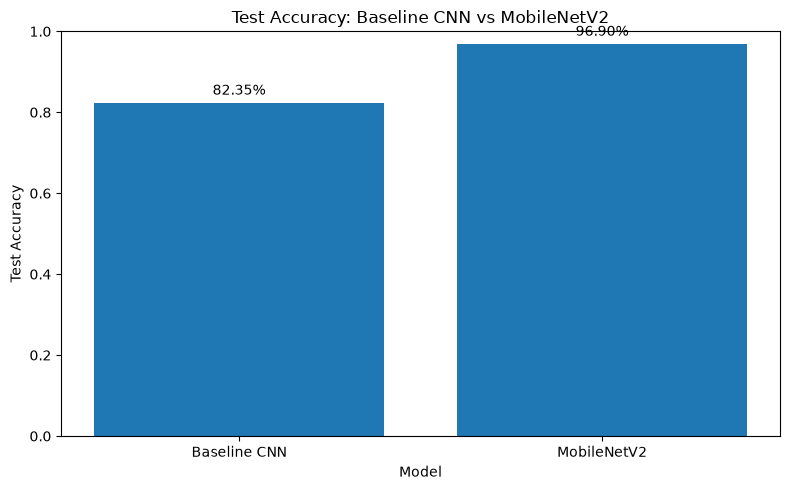

In [19]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Test Accuracy"]
)

plt.title("Test Accuracy: Baseline CNN vs MobileNetV2")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(model_comparison["Test Accuracy"]):
    plt.text(i, value + 0.02, f"{value:.2%}", ha="center")

plt.tight_layout()
plt.savefig("../dataset/model_accuracy_comparison.png", dpi=300)
plt.show()

In [20]:
from pathlib import Path

files_to_check = [
    "../models/cnn_baseline.keras",
    "../models/mobilenetv2.keras",
    "../dataset/mobilenetv2_results.csv",
    "../dataset/mobilenetv2_classification_report.csv",
    "../dataset/model_comparison.csv",
    "../dataset/model_accuracy_comparison.png"
]

for file in files_to_check:
    path = Path(file)
    print(f"{file}: {'Found' if path.exists() else 'Missing'}")

../models/cnn_baseline.keras: Found
../models/mobilenetv2.keras: Found
../dataset/mobilenetv2_results.csv: Found
../dataset/mobilenetv2_classification_report.csv: Found
../dataset/model_comparison.csv: Found
../dataset/model_accuracy_comparison.png: Found
